In [ ]:
# Cell 1: Check GPU availability
import torch
print("CUDA available:", torch.cuda.is_available())
print("Device name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

CUDA available: True
Device name: Tesla T4


In [ ]:
# Cell 2: Locate the dataset ZIP file
import os

# Check both possible locations
for p in ['/content/dataset.zip', '/dataset.zip']:
    if os.path.exists(p):
        print(f"✅ Found: {p}  ({os.path.getsize(p)/1024/1024:.1f} MB)")
        zip_path = p
    else:
        print(f"❌ Not at: {p}")

❌ Not at: /content/dataset.zip
✅ Found: /dataset.zip  (237.1 MB)


In [ ]:
# Cell 3: Extract the dataset ZIP into /content/dataset
import zipfile, os, shutil

zip_path = '/dataset.zip'              # ← correct path confirmed
extract_path = '/content/dataset'

# Clean any empty leftover folder first
shutil.rmtree(extract_path, ignore_errors=True)
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(extract_path)

print("✅ Extraction complete. Top-level contents of /content/dataset:")
print(os.listdir(extract_path))

✅ Extraction complete. Top-level contents of /content/dataset:
['splited_dataset']


In [ ]:
# Cell 4: Inspect dataset folder structure
import os
path = '/content/dataset'

print("=== Contents of", path, "===")
for item in sorted(os.listdir(path)):
    full = os.path.join(path, item)
    if os.path.isdir(full):
        sub = sorted(os.listdir(full))
        print(f"📁 {item}/  → {len(sub)} items  → first 5: {sub[:5]}")
    else:
        print(f"📄 {item}")

=== Contents of /content/dataset ===
📁 splited_dataset/  → 2 items  → first 5: ['test', 'train']


In [ ]:
# Cell 5: Core imports and device selection
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)

cuda


In [ ]:
# Cell 6: Set path to the train/test split folder
import os
path = '/content/dataset/splited_dataset'
print("Contents:", os.listdir(path))

Contents: ['test', 'train']


In [ ]:
# Cell 7: Define transforms and load train/test datasets
import torchvision.transforms as transforms

train_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor()
])

val_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
])

train_folder = path + '/train'
test_folder  = path + '/test'

train_data = datasets.ImageFolder(train_folder, transform = train_transform)
test_data  = datasets.ImageFolder(test_folder,  transform = val_transform)
print(f"Trn:{len(train_data)}")
print(f"Tst:{len(test_data)}")
print(f"Classes ({len(train_data.classes)}): {train_data.classes}")

Trn:3106
Tst:752
Classes (48): ['Daiatsu_Core', 'Daiatsu_Hijet', 'Daiatsu_Mira', 'FAW_V2', 'FAW_XPV', 'Honda_BRV', 'Honda_City_aspire', 'Honda_Grace', 'Honda_Vezell', 'Honda_city_1994', 'Honda_city_2000', 'Honda_civic_1994', 'Honda_civic_2005', 'Honda_civic_2007', 'Honda_civic_2015', 'Honda_civic_2018', 'KIA_Sportage', 'Suzuki_Every', 'Suzuki_Mehran', 'Suzuki_alto_2007', 'Suzuki_alto_2019', 'Suzuki_alto_japan_2010', 'Suzuki_carry', 'Suzuki_cultus_2018', 'Suzuki_cultus_2019', 'Suzuki_highroof', 'Suzuki_kyber', 'Suzuki_liana', 'Suzuki_margala', 'Suzuki_swift', 'Suzuki_wagonR_2015', 'Toyota HIACE 2000', 'Toyota_Aqua', 'Toyota_Hiace_2012', 'Toyota_Landcruser', 'Toyota_Passo', 'Toyota_Prado', 'Toyota_Vigo', 'Toyota_Vitz', 'Toyota_Vitz_2010', 'Toyota_axio', 'Toyota_corolla_2000', 'Toyota_corolla_2007', 'Toyota_corolla_2011', 'Toyota_corolla_2016', 'Toyota_fortuner', 'Toyota_pirus', 'Toyota_premio']


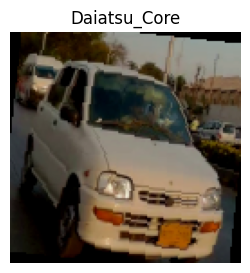

In [ ]:
# Cell 8: Display a sample image from the training set
plt.figure(figsize = (3,3))
img, label = train_data[0]
plt.imshow(img.permute(1,2,0))
plt.title(train_data.classes[label])
plt.axis('off')
plt.show()

In [ ]:
# Cell 9: Define training hyperparameters
# Hyperparameters
batch_size = 32
learning_rate = 0.001
minimum_learning_rate = 1e-4
epochs = 35

In [ ]:
# Cell 10: Create DataLoaders for train and test sets
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)

print(f"Train batches: {len(train_loader)}")
print(f"Test batches : {len(test_loader)}")

Train batches: 98
Test batches : 24


In [ ]:
# Cell 11: Define the custom CNN architecture
class CNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 16 * 16, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        x = self.conv(x)
        x = self.fc(x)
        return x

In [ ]:
# Cell 12: Instantiate the CNN model and move to device
model = CNN(num_classes=len(train_data.classes)).to(device)
print(model)

CNN(
  (conv): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=32768, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=256, out_features=48, bias=True)
  )
)


In [ ]:
# Cell 13: Define loss function, optimizer, and LR scheduler
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=3, min_lr=minimum_learning_rate
)

In [ ]:
# Cell 14: Define single-epoch training and validation functions
def train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0
    correct = 0
    total = 0
    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        total_loss += loss.item()

        # compute accuracy
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_loss = total_loss / len(loader)
    train_acc = correct / total

    return train_loss, train_acc


def validate_epoch(model, loader, criterion, device):
    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item()

            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    val_loss = total_loss / len(loader)
    val_acc = correct / total

    return val_loss, val_acc

In [ ]:
# Cell 15: Full training loop over all epochs
train_losses, val_losses = [], []
train_accs, val_accs = [], []

for epoch in range(epochs):
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, val_acc = validate_epoch(model, test_loader, criterion, device)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    scheduler.step(val_loss)

    print(f"Epoch {epoch+1}/{epochs} | "
          f"Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")

torch.save(model.state_dict(), "/content/vehicle_cnn.pth")

Epoch 1/35 | Train Loss: 3.6627 Acc: 0.0818 | Val Loss: 3.5863 Acc: 0.0931
Epoch 2/35 | Train Loss: 3.5890 Acc: 0.0995 | Val Loss: 3.5282 Acc: 0.1051
Epoch 3/35 | Train Loss: 3.4946 Acc: 0.1310 | Val Loss: 3.4155 Acc: 0.1529
Epoch 4/35 | Train Loss: 3.3077 Acc: 0.1632 | Val Loss: 3.2301 Acc: 0.1729
Epoch 5/35 | Train Loss: 3.2196 Acc: 0.1803 | Val Loss: 3.1148 Acc: 0.2154
Epoch 6/35 | Train Loss: 3.0620 Acc: 0.2064 | Val Loss: 2.9283 Acc: 0.2380
Epoch 7/35 | Train Loss: 2.9730 Acc: 0.2154 | Val Loss: 2.8557 Acc: 0.2872
Epoch 8/35 | Train Loss: 2.8315 Acc: 0.2418 | Val Loss: 2.7603 Acc: 0.2806
Epoch 9/35 | Train Loss: 2.6934 Acc: 0.2727 | Val Loss: 2.6659 Acc: 0.3125
Epoch 10/35 | Train Loss: 2.6118 Acc: 0.2885 | Val Loss: 2.5669 Acc: 0.3431
Epoch 11/35 | Train Loss: 2.5207 Acc: 0.3030 | Val Loss: 2.4545 Acc: 0.3551
Epoch 12/35 | Train Loss: 2.4159 Acc: 0.3451 | Val Loss: 2.3562 Acc: 0.3883
Epoch 13/35 | Train Loss: 2.2999 Acc: 0.3667 | Val Loss: 2.2630 Acc: 0.4215
Epoch 14/35 | Train L

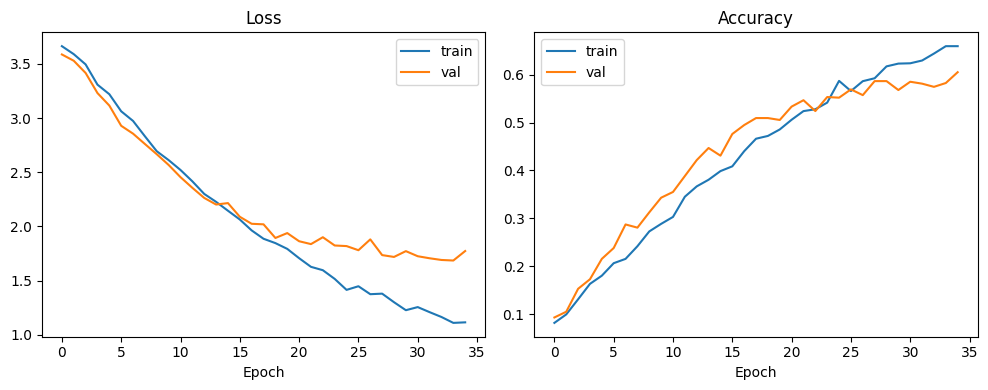

In [ ]:
# Cell 16: Plot training and validation loss/accuracy curves
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label='train')
plt.plot(val_losses, label='val')
plt.legend()
plt.title('Loss')
plt.xlabel('Epoch')

plt.subplot(1, 2, 2)
plt.plot(train_accs, label='train')
plt.plot(val_accs, label='val')
plt.legend()
plt.title('Accuracy')
plt.xlabel('Epoch')

plt.tight_layout()
plt.show()

In [ ]:
# Cell 17: Load best model and compute final test metrics
from sklearn.metrics import classification_report, accuracy_score, f1_score

model.load_state_dict(torch.load("/content/vehicle_cnn.pth"))
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(device))
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

print("Test Accuracy:", accuracy_score(all_labels, all_preds))
print("Macro F1     :", f1_score(all_labels, all_preds, average='macro'))
print("\nClassification Report:\n")
print(classification_report(all_labels, all_preds, target_names=train_data.classes))

Test Accuracy: 0.6050531914893617
Macro F1     : 0.4786458527547747

Classification Report:

                        precision    recall  f1-score   support

          Daiatsu_Core       0.67      0.70      0.68        20
         Daiatsu_Hijet       0.67      0.60      0.63        10
          Daiatsu_Mira       0.58      0.55      0.56        20
                FAW_V2       0.67      0.29      0.40         7
               FAW_XPV       1.00      0.67      0.80         6
             Honda_BRV       1.00      0.50      0.67         6
     Honda_City_aspire       0.45      0.50      0.47        26
           Honda_Grace       1.00      0.20      0.33         5
          Honda_Vezell       0.67      0.44      0.53         9
       Honda_city_1994       0.00      0.00      0.00         7
       Honda_city_2000       0.55      0.35      0.43        17
      Honda_civic_1994       0.00      0.00      0.00         4
      Honda_civic_2005       0.00      0.00      0.00         8
      Hond

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


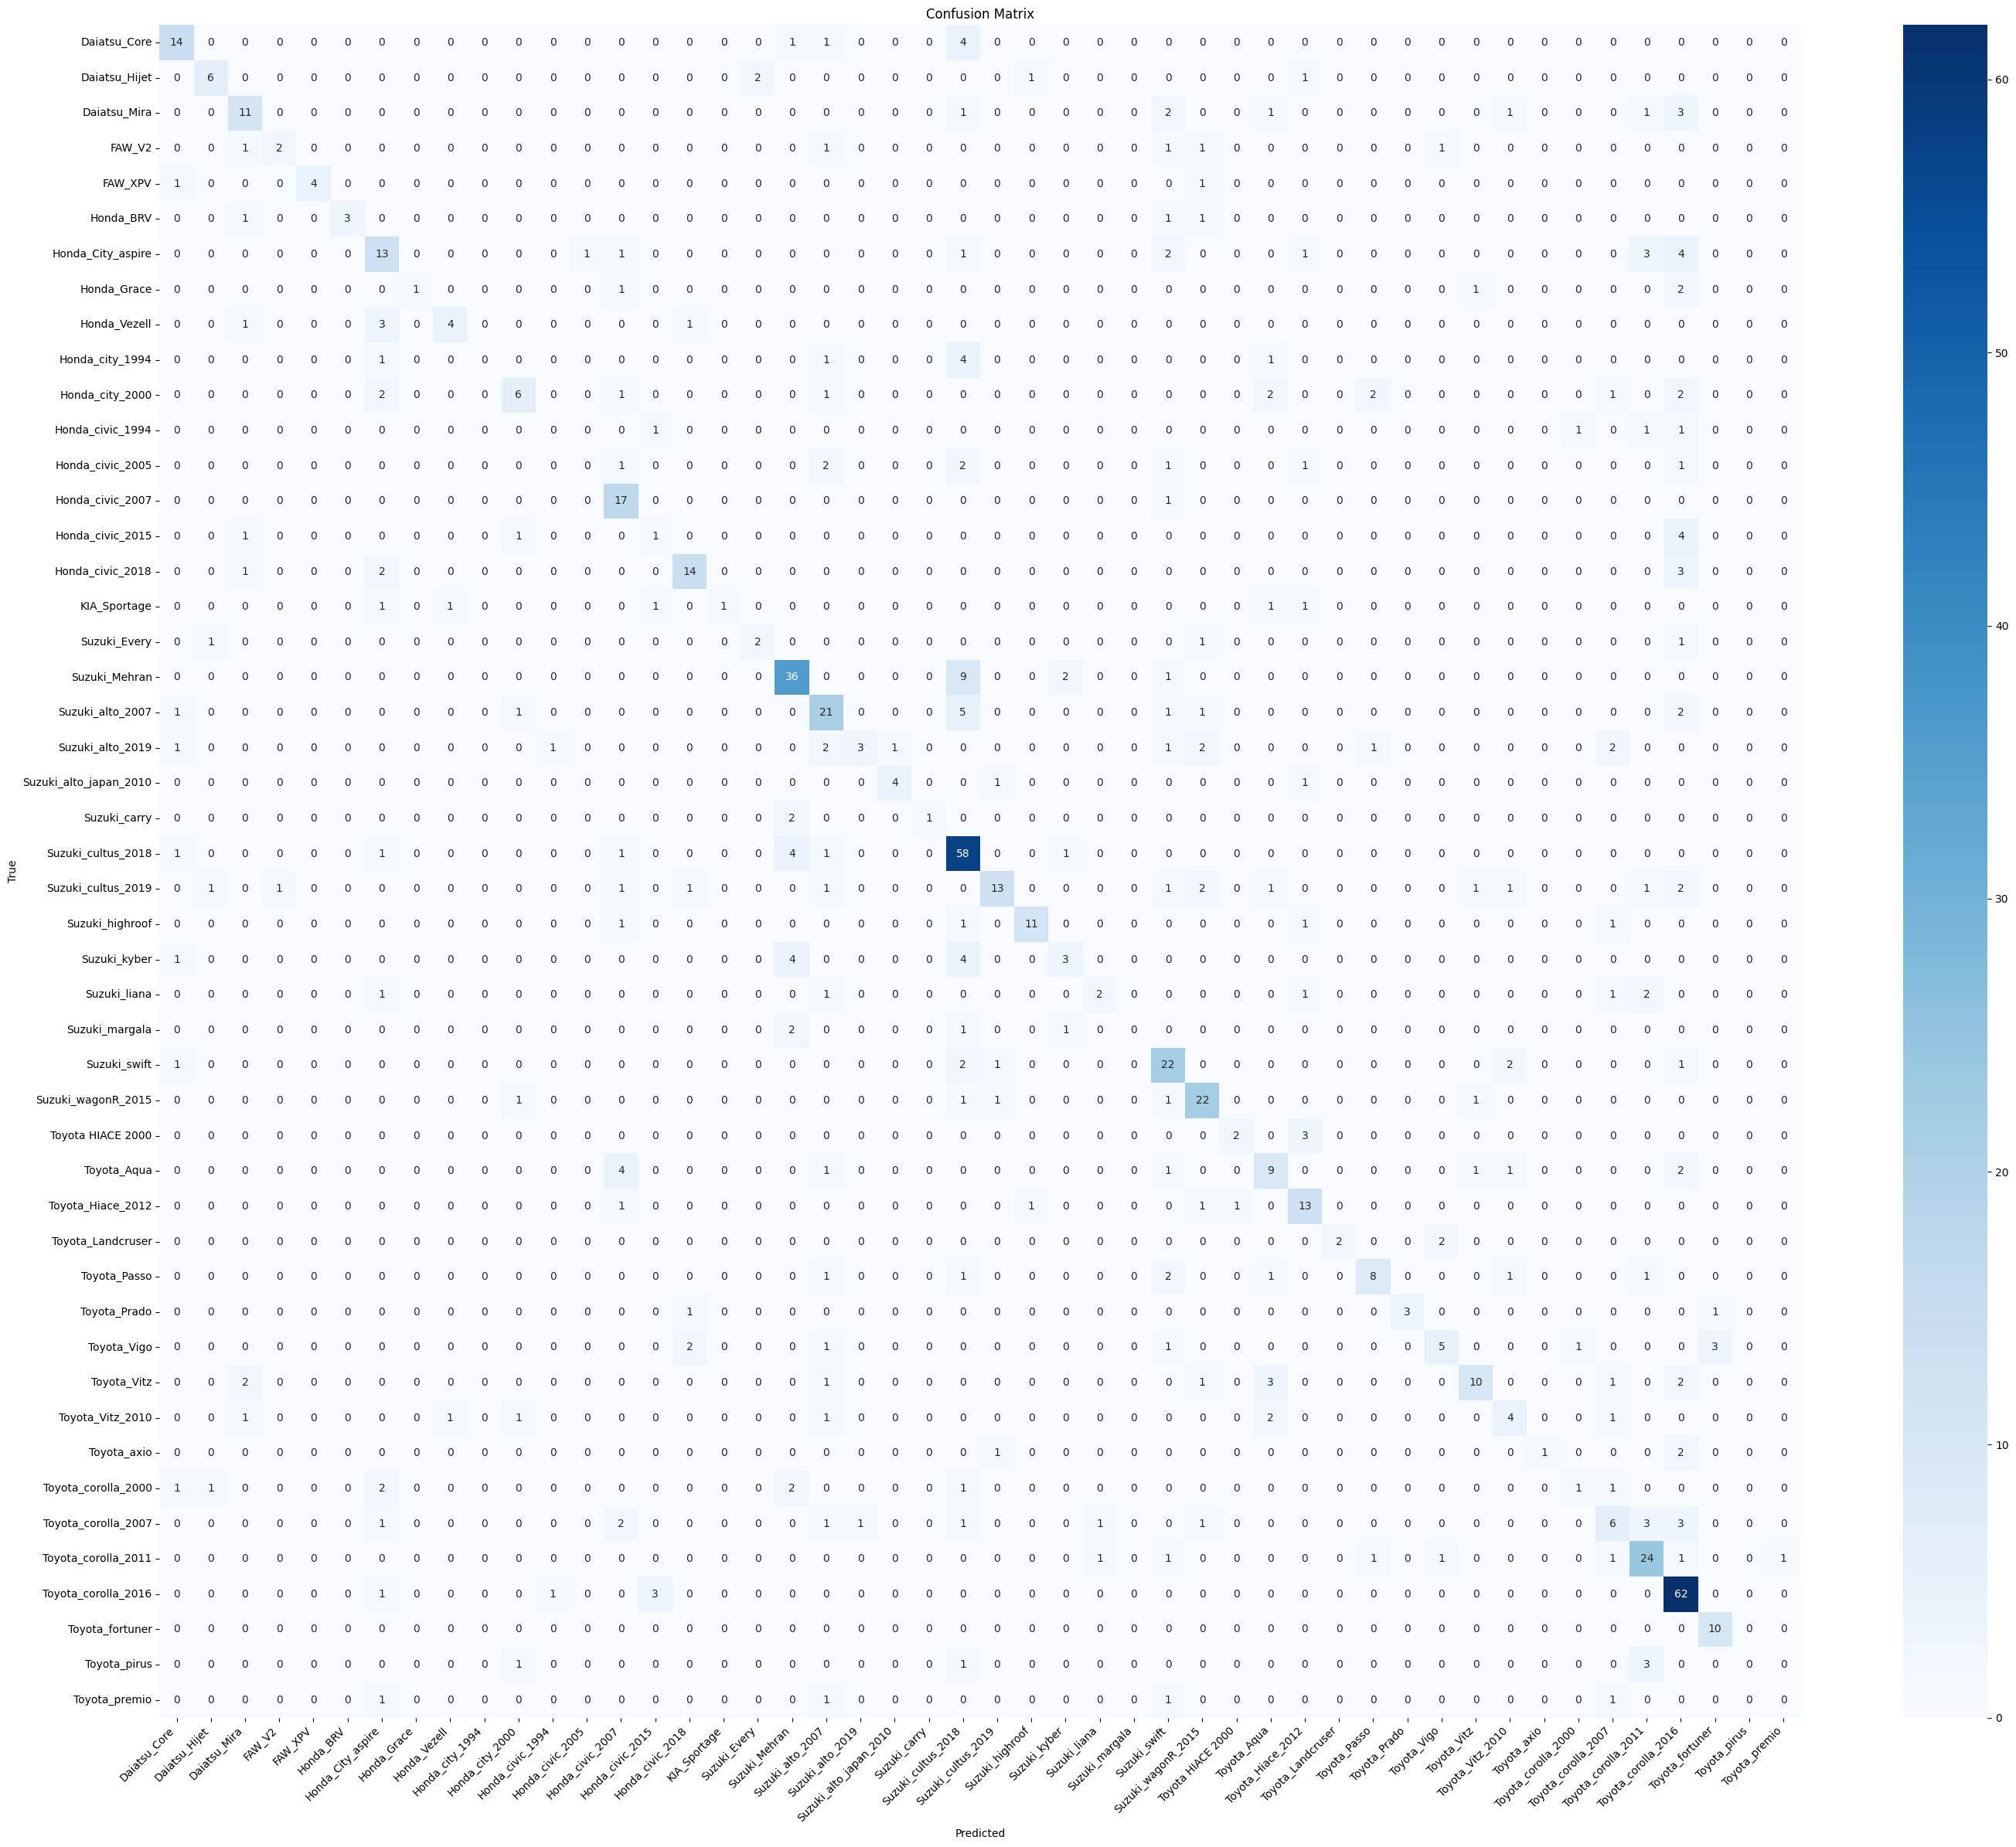

In [ ]:
# Cell 18: Plot confusion matrix heatmap
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(max(10, len(train_data.classes)*0.6),
                    max(8,  len(train_data.classes)*0.5)))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=train_data.classes,
            yticklabels=train_data.classes)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

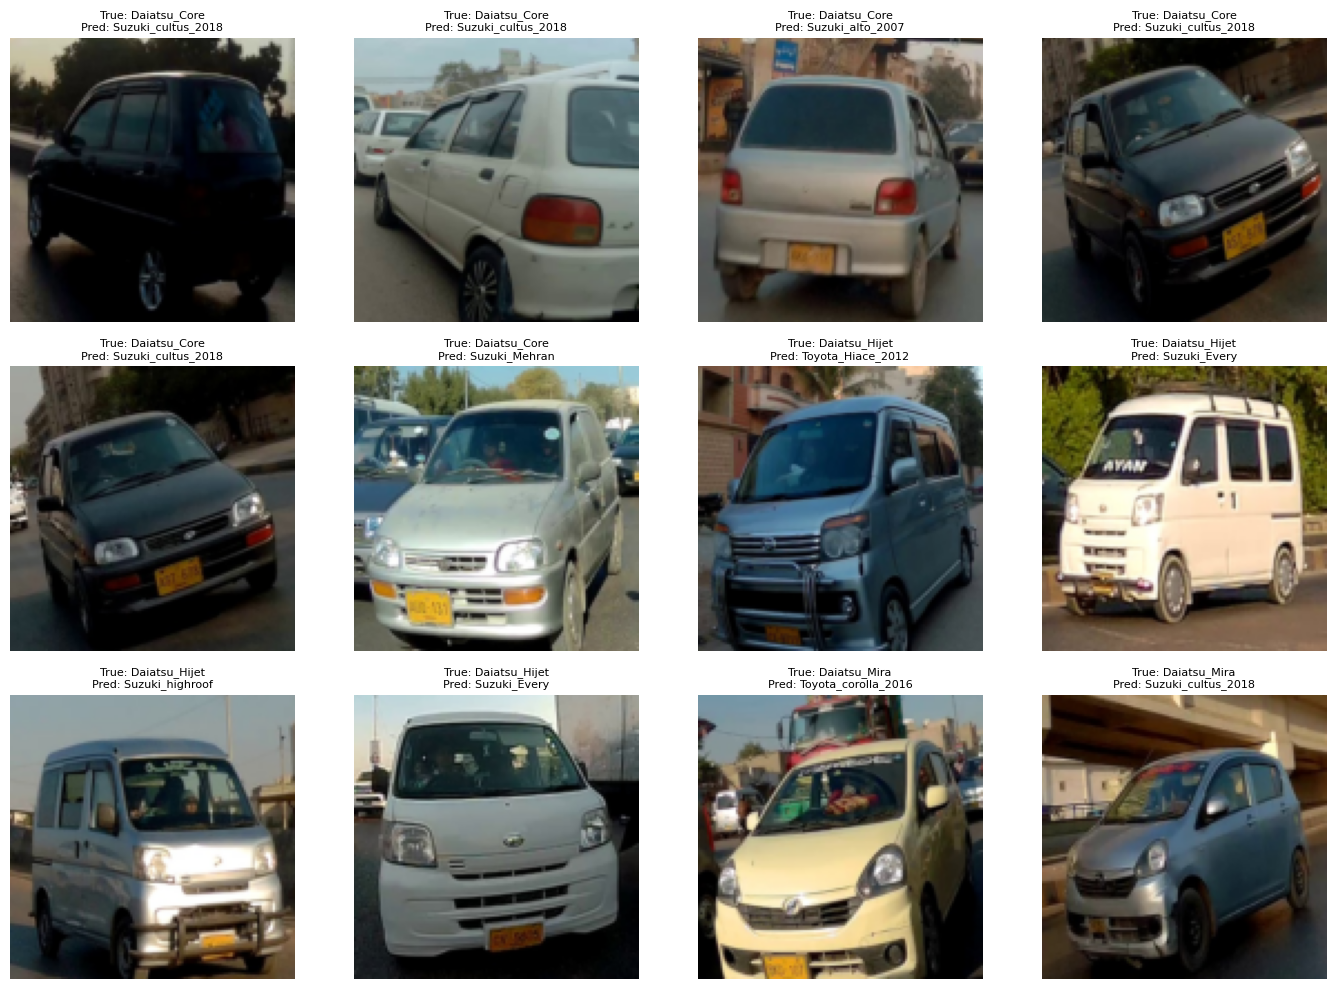

In [ ]:
# Cell 19: Display a grid of misclassified test images
model.eval()
misclassified = []
with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(device))
        _, preds = torch.max(outputs, 1)
        for i in range(len(labels)):
            if preds[i].item() != labels[i].item():
                misclassified.append((images[i], labels[i].item(), preds[i].item()))
        if len(misclassified) >= 12:
            break

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for i, ax in enumerate(axes.flat):
    if i >= len(misclassified):
        ax.axis('off')
        continue
    img, true_lbl, pred_lbl = misclassified[i]
    ax.imshow(img.permute(1, 2, 0).numpy())
    ax.set_title(f"True: {train_data.classes[true_lbl]}\nPred: {train_data.classes[pred_lbl]}", fontsize=8)
    ax.axis('off')

plt.tight_layout()
plt.show()